# Module 2: Deep Agents

> Part of the **Modular Workshops** series. Standalone, ~45 min.

Deep Agents = `create_agent()` + a pre-built middleware stack (filesystem, planning, subagents, context management). We'll build up from a bare agent to a fully-featured research assistant, exploring:

- The harness and built-in tools
- Custom tools (web research via Anthropic's web search tool)
- Subagents and context isolation
- Backends and persistent memory
- Middleware (compliance, audit)
- Human-in-the-loop on tool calls
- AGENTS.md and Skills


## Setup

In [1]:
import sys
from pathlib import Path
project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from utils.models import model

from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Command
from langsmith import uuid7
from IPython.display import Image, display

# Start each run with a clean long-term memory store (section 1.4 recreates it).
for f in Path().glob("deep_agents_memory.db*"):
    f.unlink()

print("Ready")

Ready


---
# Part 1: Deep Agents

Deep Agents = `create_agent()` + a pre-built middleware stack (filesystem, planning, subagents, context management).

We'll build up from a bare agent to a fully-featured research assistant.

## 1.1 Your First Deep Agent

`create_deep_agent()` gives you a filesystem, a todo list, and context management out of the box — no tools required.

<img src="../images/deepAgentsDiag.png" style="width: auto; max-height: 420px; border-radius: 8px;">

### What you get for free:

- **Filesystem Tools** — `ls`, `read_file`, `write_file`, `edit_file`, `glob`, `grep`
- **Planning Tool** — `write_todos` for task tracking
- **Subagent Delegation** — `task()` tool for isolated work
- **Large Tool Result Eviction** — Automatically offloads tool results >20k tokens to the filesystem
- **Conversation Summarization** — Compresses history when approaching ~85% context capacity
- **Dangling Tool Call Patching** — Fixes message history consistency automatically


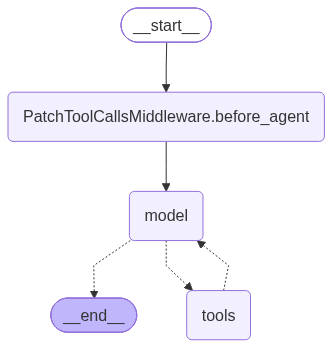

In [2]:
from deepagents import create_deep_agent

agent = create_deep_agent(
    model=model,
    system_prompt="You are a helpful assistant.",
    checkpointer=MemorySaver(),
)
agent

In [3]:
# The agent can already write and read files — these are built-in tools
config = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Write a haiku about AI to /haiku.txt, then read it back to me."}]
}, config=config)

for m in result["messages"]:
    m.model_copy(update={"content": m.text}).pretty_print()

================================ Human Message =================================

Write a haiku about AI to /haiku.txt, then read it back to me.
================================== Ai Message ==================================
Tool Calls:
  write_file (call_szwHL0pOwiQsWT5BpJT019E2)
 Call ID: call_szwHL0pOwiQsWT5BpJT019E2
  Args:
    file_path: /haiku.txt
    content: Silent circuits dream
Learning from the human spark
New worlds bloom in code
================================= Tool Message =================================
Name: write_file

Updated file /haiku.txt
================================== Ai Message ==================================
Tool Calls:
  read_file (call_NL406cR1WXlwf7ZNkT62hYyp)
 Call ID: call_NL406cR1WXlwf7ZNkT62hYyp
  Args:
    file_path: /haiku.txt
    offset: 0
    limit: 100
================================= Tool Message =================================
Name: read_file

1  Silent circuits dream
2  Learning from the human spark
3  New worlds bloom in code
======

In [4]:
# Helper: print the virtual filesystem from a deep agent result.
def print_files(result, header="VIRTUAL FILESYSTEM (in-memory, not on disk!)"):
    files = result.get("files") or {}
    if not files:
        print("(no files in state)")
        return
    print("=" * 50)
    print(header)
    print("=" * 50)
    for path, file_data in files.items():
        print(f"\n  Path: {path!r}")
        print("  " + "-" * 38)
        content = file_data
        if isinstance(file_data, dict) and "content" in file_data:
            content = file_data["content"]
        if isinstance(content, list):
            content = "\n".join(content)
        for line in str(content).split("\n"):
            print(f"  | {line}")

print_files(result)


VIRTUAL FILESYSTEM (in-memory, not on disk!)

  Path: '/haiku.txt'
  --------------------------------------
  | Silent circuits dream
  | Learning from the human spark
  | New worlds bloom in code
  | 


### Filesystem persistence within a thread

By default, `create_deep_agent()` uses **StateBackend** — files are stored in agent state and persist within a thread (via the checkpointer), but disappear when you start a new thread.

| Backend | Storage | Persistence | Use Case |
|---------|---------|-------------|----------|
| **StateBackend** | In-memory (agent state) | Single thread | Scratch pads, intermediate results |
| **FilesystemBackend** | Local disk | Permanent | Direct file access (use with caution) |
| **StoreBackend** | LangGraph Store | Cross-thread | Long-term memories |
| **CompositeBackend** | Routes to others | Mixed | Selective persistence |

In [5]:
# Same thread — the file persists via the checkpointer
result = agent.invoke({
    "messages": [{"role": "user", "content": "Read the file /haiku.txt"}]
}, config=config)

print("Same thread:\n\n", result["messages"][-1].text)

Same thread:

 Silent circuits dream  
Learning from the human spark  
New worlds bloom in code


In [6]:
# New thread — StateBackend is ephemeral, so the file is gone
new_config = {"configurable": {"thread_id": str(uuid7())}}

result = agent.invoke({
    "messages": [{"role": "user", "content": "List all files with ls /"}]
}, config=new_config)

print("New thread:", result["messages"][-1].text)

New thread: No files found in `/`.


### Key Takeaway
- `create_deep_agent()` gives you filesystem + planning capabilities for free
- Files are stored in agent state (virtual, not on disk)
- `StateBackend` (default) persists within a thread but is ephemeral across threads
- We'll see how to make files persist across threads with `CompositeBackend` + `StoreBackend` in section 1.4

## 1.2 Custom Tools

Add your own tools alongside the built-in ones. We define `web_research` inline with `@tool` so the pattern stays visible; the body delegates to `resilient_web_research` from `utils/search.py`, which answers the question with live web search through **Anthropic's server-side web search tool**, retries on failure, and falls back to a canned response so the demo doesn't break on a flaky network.


In [7]:
from utils.search import resilient_web_research

@tool(parse_docstring=True)
def web_research(query: str) -> str:
    """Research a question on the web and return a cited answer.

    Args:
        query: The question or topic to research.
    """
    # `resilient_web_research` asks Claude to answer with its server-side
    # web_search tool, retries on failure, and falls back to a topic-matched
    # canned response. See utils/search.py.
    return resilient_web_research(query, max_retries=2)

agent = create_deep_agent(
    model=model,
    tools=[web_research],
    system_prompt="You are a helpful research assistant.",
    checkpointer=MemorySaver(),
)

config = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "What is Deep Agents? Write a one-paragraph summary to /summary.md"}]
}, config=config)

print("Agent reply:", result["messages"][-1].text)

Agent reply: Written a one-paragraph summary to `/summary.md`.


In [8]:
# Print state of virtual file system
print_files(result)

VIRTUAL FILESYSTEM (in-memory, not on disk!)

  Path: '/summary.md'
  --------------------------------------
  | Deep Agents is LangChain’s opinionated framework for building complex, long-running LLM agents. Built on LangChain and LangGraph, it extends the basic model-and-tool loop with integrated planning, virtual filesystem tools, context summarization and offloading, subagent delegation, memory, skills, permissions, human approval, and optional sandboxed shell execution. These capabilities make it useful for deep research, coding, data analysis, document processing, and other multi-step tasks that require persistent context or coordination; for simpler agents, standard LangChain is more lightweight, while LangGraph offers lower-level control over execution graphs and state transitions.


## 1.3 Subagents: Isolated Delegation

Subagents run in a separate context. The main agent delegates via `task()` and only sees the final result — keeping the main context clean.

<img src="../images/deepAgentSubagents.png" style="width: auto; max-height: 380px; border-radius: 8px;">


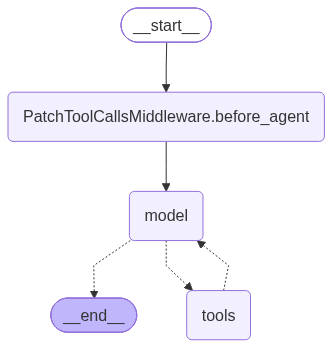

In [9]:
from datetime import datetime

research_subagent = {
    "name": "research-agent",
    "description": "Delegate research tasks. Give one topic at a time.",
    "system_prompt": f"""You are a research assistant. Today is {datetime.now().strftime('%Y-%m-%d')}.
Use tools to gather information. Structure findings with clear headings and inline citations.
Limit to 3 search calls.""",
    "tools": [web_research],
}

agent = create_deep_agent(
    model=model,
    system_prompt="""You are a research coordinator.
Delegate research to the research-agent using the task() tool.
Synthesize findings and write a report.""",
    subagents=[research_subagent],
    checkpointer=MemorySaver(),
)
agent

In [10]:
config = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Lightly research the latest news on AI agents this week"}]
}, config=config)

def truncate(text, limit=1000):
    return text if len(text) <= limit else text[:limit] + "…"

for m in result["messages"]:
    m.model_copy(update={"content": truncate(m.text)}).pretty_print()

================================ Human Message =================================

Lightly research the latest news on AI agents this week
================================== Ai Message ==================================
Tool Calls:
  task (call_45OXil48spAT04QSvve1q2GR)
 Call ID: call_45OXil48spAT04QSvve1q2GR
  Args:
    description: Research the latest news on AI agents from this week. Use current web-accessible sources if available, prioritize reputable outlets and official announcements, and identify the publication date, key development, organizations involved, and source URL for each item. Focus on genuinely new developments in the current calendar week; note if current-week coverage is sparse or date ambiguity exists. Return a concise, sourced bullet list and a short synthesis. Do not invent facts or URLs.
    subagent_type: research-agent
================================= Tool Message =================================
Name: task

## AI-agent news this week (October 26–28, 2026)



## 1.4 Backends & Memory

By default, files live in ephemeral state (`StateBackend`). Use `CompositeBackend` to route paths — e.g. `/memories/` to persistent `StoreBackend` while everything else stays ephemeral.

`StoreBackend` is a database-backed store meant to persist memory across threads. Here we back it with a local SQLite file, but the LangGraph `Store` can be backed by the database of your choice (Postgres, etc.).

`StoreBackend` scopes what it reads and writes by `namespace` — a required argument, and your lever for isolation: per user, per assistant, or shared across everyone as here.


In [11]:
import sqlite3
from deepagents.backends import StateBackend, StoreBackend, CompositeBackend
from langgraph.store.sqlite import SqliteStore

MEMORY_DB = "deep_agents_memory.db"

def open_memory_store(path=MEMORY_DB):
    """Open (or create) a persistent SQLite-backed long-term memory store."""
    conn = sqlite3.connect(path, check_same_thread=False, isolation_level=None)
    store = SqliteStore(conn)
    store.setup()  # creates tables IF NOT EXISTS -> safe whether or not the DB exists
    return store

store = open_memory_store()

# Pass a CompositeBackend *instance* (not a factory)
backend = CompositeBackend(
    default=StateBackend(),                                  # ephemeral scratch space
    routes={
        "/memories/": StoreBackend(                          # persists across threads (SQLite on disk)
            store=store,
            namespace=lambda rt: ("memories", "shared"),
        ),
    },
)

agent = create_deep_agent(
    model=model,
    tools=[web_research],
    system_prompt=(
        "You are a helpful assistant. Save important facts to /memories/ for future reference. "
        "ALWAYS check /memories files before answering any questions to ensure you don't miss relevant information."
    ),
    subagents=[research_subagent],
    backend=backend,
    store=store,
    checkpointer=MemorySaver(),
)

# Thread 1: agent saves a memory
config1 = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Remember that my favorite programming language is Python. Save this to /memories/preferences.md"}]
}, config=config1)
print("Thread 1:", result["messages"][-1].text)


Thread 1: Saved to `/memories/preferences.md`: your favorite programming language is Python.


In [12]:
# Thread 2: different thread, but /memories/ persists via StoreBackend
config2 = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "What's my favorite programming language? Check /memories/"}]
}, config=config2)
print("Thread 2:", result["messages"][-1].text)

Thread 2: Your favorite programming language is **Python**.


## 1.5 Middleware: Pluggable Behavior

Middleware hooks into `wrap_model_call` (every LLM call) and `wrap_tool_call` (every tool call). This lets you inject rules, audit, or intercept without changing agent code.

<img src="../images/deepAgentMiddleware.png" style="width: auto; max-height: 380px; border-radius: 8px;">

### Built-in context management

Three strategies the deep-agent middleware uses to keep within the model's context window:

<img src="../images/Offloading Inputs LangChain.png" style="width: 100%; max-width: 900px; height: auto; border-radius: 8px;">

**Offload Large Inputs** — file write/edit tool calls leave the full content in conversation history. At ~85% context capacity, deep agents truncate older tool calls and replace them with a file-pointer reference.

<img src="../images/Offloading Results LangChain.png" style="width: 100%; max-width: 900px; height: auto; border-radius: 8px;">

**Offload Large Results** — tool results over ~20k tokens are written to the backend and swapped with a path + 10-line preview. The agent can re-read or grep the full content as needed.

<img src="../images/LangChain Summarization.png" style="width: 100%; max-width: 900px; height: auto; border-radius: 8px;">

**Conversation Summarization** — when there's nothing left to offload and context hits ~85% of `max_input_tokens`, history is summarized. Full messages move to `/conversation_history/`; a structured summary replaces them in working memory.


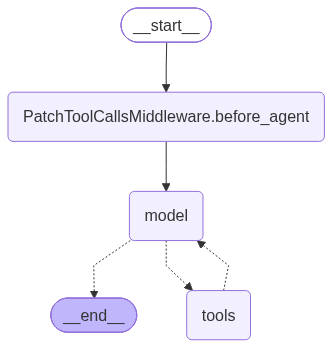

In [ ]:
from langchain.agents.middleware import wrap_model_call, wrap_tool_call
from langchain_core.messages import SystemMessage

audit_log = []

@wrap_model_call
def compliance_rules(request, handler):
    """Inject compliance rules into every LLM call."""
    rules = """## Compliance Rules
- Never include SSNs, credit card numbers, or account passwords in responses
- Always cite sources when presenting research findings
- Flag any request involving non-public financial information"""
    existing = request.system_message
    blocks = list(existing.content_blocks) if existing else []
    blocks.append({"type": "text", "text": f"\n\n{rules}"})
    return handler(request.override(system_message=SystemMessage(content_blocks=blocks)))

@wrap_tool_call
def audit_trail(request, handler):
    """Create an audit log entry for every tool call."""
    entry = {"tool": request.tool_call["name"], "timestamp": datetime.now().isoformat()}
    result = handler(request)
    entry["status"] = "success"
    audit_log.append(entry)
    return result

agent_with_middleware = create_deep_agent(
    model=model,
    tools=[web_research],
    system_prompt="You are a helpful research assistant.",
    middleware=[compliance_rules, audit_trail],
    checkpointer=MemorySaver(),
)


In [13]:
config = {"configurable": {"thread_id": str(uuid7())}}
result = agent_with_middleware.invoke({
    "messages": [{"role": "user", "content": "What is LangGraph? Write a short summary to /summary.md"}]
}, config=config)

print(result["messages"][-1].text)
print(f"\n--- Audit Log ({len(audit_log)} entries) ---")
for entry in audit_log:
    print(f"  {entry['timestamp']}  {entry['tool']}  {entry['status']}")

Wrote a short summary of LangGraph to [`/summary.md`](/summary.md).

--- Audit Log (3 entries) ---
  2026-10-28T12:47:35.385946  ls  success
  2026-10-28T12:47:37.421248  web_research  success
  2026-10-28T12:47:47.820591  write_file  success


## 1.6 HITL: Tool-Level Approval

Deep Agents supports `interrupt_on` — pause execution when specific tools are called. The human can approve, edit, or reject.

<img src="../images/deepAgentHITL.png" style="width: auto; max-height: 380px; border-radius: 8px;">


In [14]:
agent_with_hitl = create_deep_agent(
    model=model,
    tools=[web_research],
    system_prompt="You are a helpful research assistant.",
    checkpointer=MemorySaver(),
    interrupt_on={
        "write_file": True,
        "edit_file": True,
    },
)

config = {"configurable": {"thread_id": str(uuid7())}}
result = agent_with_hitl.invoke({
    "messages": [{"role": "user", "content": "Write a file called /test.md with 'Hello World'"}]
}, config=config)

if result.get("__interrupt__"):
    interrupt_info = result["__interrupt__"][0].value
    for action in interrupt_info["action_requests"]:
        print(f"Paused — tool: {action['name']}, args: {action['args']}")
    print("\nWaiting for approval...")
    

Paused — tool: write_file, args: {'file_path': '/test.md', 'content': 'Hello World'}

Waiting for approval...


In [15]:
# Approve and continue
if result.get("__interrupt__"):
    result = agent_with_hitl.invoke(
        Command(resume={"decisions": [{"type": "approve"}]}),
        config=config,
    )
    print("Approved!")
    print("Agent reply:", result["messages"][-1].text)
    print()
    print_files(result)


Approved!
Agent reply: Created `/test.md` with the content:

```text
Hello World
```

VIRTUAL FILESYSTEM (in-memory, not on disk!)

  Path: '/test.md'
  --------------------------------------
  | Hello World


## 1.7 AGENTS.md & Skills

`AGENTS.md` replaces hardcoded system prompts with an editable identity file. Skills are loaded on demand — the agent reads them only when the task matches.

In [16]:
from deepagents.backends.utils import create_file_data

agents_md = """# Research Assistant

You are an expert research assistant.

## Workflow
1. Plan with write_todos
2. Delegate research to research-agent via task()
3. Synthesize findings into a report
4. Save to /final_report.md

## Rules
- Delegate research, don't search directly
- Consolidate citations [1], [2], [3]
- Check /skills/ for content format instructions
"""

linkedin_skill = """---
name: linkedin-post
description: Write a LinkedIn post. Use when asked for LinkedIn content or thought leadership.
---

# LinkedIn Post Skill

- Bold hook as first line (before the "see more" cut)
- 3-5 short paragraphs with 1-2 emojis each
- End with a CTA or question
- 3-5 hashtags at the bottom
- 150-300 words
"""

# The agent's identity lives in the /AGENTS.md file (seeded below) and is loaded
# via the `memory` parameter — no redundant `system_prompt` string.
agent = create_deep_agent(
    model=model,
    tools=[web_research],
    subagents=[research_subagent],
    memory=["/AGENTS.md"],
    skills=["/skills/"],
    checkpointer=MemorySaver(),
)

config = {"configurable": {"thread_id": uuid7()}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Research AI agents briefly, then write a LinkedIn post about it. Do not call write_todos, just do it."}],
    "files": {
        "/AGENTS.md": create_file_data(agents_md),
        "/skills/linkedin-post/SKILL.md": create_file_data(linkedin_skill),
    },
}, config=config)

for m in result["messages"]:
    m.model_copy(update={"content": truncate(m.text)}).pretty_print()

================================ Human Message =================================

Research AI agents briefly, then write a LinkedIn post about it. Do not call write_todos, just do it.
================================== Ai Message ==================================
Tool Calls:
  read_file (call_wKa4oA3tZPyXxaFF5ezHxH8h)
 Call ID: call_wKa4oA3tZPyXxaFF5ezHxH8h
  Args:
    file_path: /skills/linkedin-post/SKILL.md
    offset: 0
    limit: 1000
================================= Tool Message =================================
Name: read_file

 1  ---
 2  name: linkedin-post
 3  description: Write a LinkedIn post. Use when asked for LinkedIn content or thought leadership.
 4  ---
 5  
 6  # LinkedIn Post Skill
 7  
 8  - Bold hook as first line (before the "see more" cut)
 9  - 3-5 short paragraphs with 1-2 emojis each
10  - End with a CTA or question
11  - 3-5 hashtags at the bottom
12  - 150-300 words
================================== Ai Message ==================================
Tool Call

## 1.8 The Complete Agent

All pieces together: tools, subagents, memory, middleware, HITL, AGENTS.md, and skills.


In [17]:
store = open_memory_store()  # same SQLite-backed long-term memory as section 1.4
audit_log = []  # reset

complete_backend = CompositeBackend(
    default=StateBackend(),
    routes={
        "/memories/": StoreBackend(
            store=store,
            namespace=lambda rt: ("memories", "shared"),
        ),
    },
)

complete_agent = create_deep_agent(
    model=model,
    tools=[web_research],
    subagents=[research_subagent],
    backend=complete_backend,
    store=store,
    middleware=[compliance_rules, audit_trail],
    checkpointer=MemorySaver(),
    interrupt_on={"write_file": True, "edit_file": True},
    memory=["/AGENTS.md"],
    skills=["/skills/"],
)

print("Complete agent created with:")
print("  - Custom tools (web_research)")
print("  - Subagents (research-agent)")
print("  - Memory (/memories/ -> StoreBackend on SQLite)")
print("  - Middleware (compliance rules + audit trail)")
print("  - HITL (interrupt on file writes)")
print("  - AGENTS.md + Skills")


Complete agent created with:
  - Custom tools (web_research)
  - Subagents (research-agent)
  - Memory (/memories/ -> StoreBackend on SQLite)
  - Middleware (compliance rules + audit trail)
  - HITL (interrupt on file writes)
  - AGENTS.md + Skills


In [18]:
# Drive the complete agent end-to-end.
# Exercises: subagent delegation, file writes (HITL-gated),
# /memories/ persistence, and middleware (audit + compliance).
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": str(uuid7())}}

# Seed AGENTS.md + the LinkedIn skill (same content as the 1.7 cell)
# so the agent has its identity and capabilities loaded.
seed_files = {
    "/AGENTS.md": create_file_data(agents_md),
    "/skills/linkedin-post/SKILL.md": create_file_data(linkedin_skill),
}

result = complete_agent.invoke({
    "messages": [HumanMessage(content=(
        "Research the LangChain v1 release briefly. "
        "Follow your AGENTS.md workflow: delegate research, write the final report to /final_report.md, "
        "and save key takeaways to /memories/research_notes.md. "
        "Search at most once."
    ))],
    "files": seed_files,
}, config=config)

# The HITL middleware pauses on every write_file / edit_file. Approve them all.
while result.get("__interrupt__"):
    payload = result["__interrupt__"][0].value
    actions = payload.get("action_requests", [])
    for action in actions:
        print(f"  HITL pause -> approving {action['name']}: {action['args'].get('file_path','?')}")
    result = complete_agent.invoke(
        Command(resume={"decisions": [{"type": "approve"} for _ in actions]}),
        config=config,
    )

print("\nFinal reply:\n", result["messages"][-1].text[:600])
print()
# Show only files the agent wrote (skip the seed files we passed in).
seed_paths = set(seed_files.keys())
agent_files = {k: v for k, v in (result.get("files") or {}).items() if k not in seed_paths}
print_files({"files": agent_files}, header="FILES THE AGENT WROTE")

print(f"\nAudit log: {len(audit_log)} tool call(s) recorded by the audit middleware")
for entry in audit_log:
    print(f"  {entry['timestamp']}  {entry['tool']:20s} {entry['status']}")


  HITL pause -> approving write_file: /final_report.md
  HITL pause -> approving write_file: /memories/research_notes.md



Final reply:
 Research completed and delegated according to the workflow.

- Final report: [`/final_report.md`](/final_report.md)
- Key takeaways: [`/memories/research_notes.md`](/memories/research_notes.md)

The report covers LangChain v1’s release timing, new agent and middleware APIs, `langchain-classic` separation, compatibility changes, migration implications, and authoritative citations.

FILES THE AGENT WROTE

  Path: '/final_report.md'
  --------------------------------------
  | # LangChain v1 Release: Brief Research Report
  | 
  | ## Summary
  | 
  | LangChain Python v1.0.0 was released on **October 17, 2025**, marking a major API transition from the 0.3.x series. The release narrows LangChain’s core focus toward production agent development and introduces a cleaner, middleware-centered architecture.
  | 
  | ## Key changes
  | 
  | - **New agent API:** `langchain.agents.create_agent` is the primary entry point and replaces `langgraph.prebuilt.create_react_agent` for the st

### Deep Agents Recap

| Feature | How | Built-in? |
|---------|-----|----------|
| **Harness** | `create_deep_agent()` | Filesystem, Planning, Summarization |
| **Custom tools** | `tools=[your_tool]` | Added to built-in tools |
| **Subagents** | `subagents=[{name, description, ...}]` | `task()` tool |
| **Memory** | `CompositeBackend` routing to `StoreBackend` | Path-based routing |
| **Middleware** | `middleware=[wrap_model_call, wrap_tool_call]` | Appended to built-in stack |
| **HITL** | `interrupt_on={"write_file": True}` | Configurable per tool |
| **AGENTS.md** | `memory=["/AGENTS.md"]` or `files={}` | Editable identity |
| **Skills** | `skills=["./skills/"]` or `files={}` | On-demand capabilities |